# Intro to Audio Processing

This notebook is adapted from **"Intro to Audio Processing"** in the
[PyTorch-Adventures](https://github.com/priyammaz/PyTorch-Adventures) repository by
[priyammaz](https://github.com/priyammaz).

Original notebook:
https://github.com/priyammaz/PyTorch-Adventures/blob/main/PyTorch%20for%20Audio/Intro%20to%20Audio%20Processing/intro_to_audio_processing.ipynb

We will explore some typical ways that we can process audio, and things to keep in mind when we are training Neural Networks on Audio data. 

When it comes to audio data, there are a few things to keep in mind about it:

- Sampling Rate (Hz): How many samples is in every second of audio?
- Duration: How many seconds is the audio?

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchaudio
import torchaudio.transforms as T
import IPython

audio, sampling_rate = torchaudio.load("audio.wav")
audio = audio.squeeze()

print("Audio:", audio)
print("Sampling Rate:", sampling_rate)
print("Total Samples in Audio:", len(audio))
print("Total Duration:", len(audio) / sampling_rate, "seconds")

IPython.display.Audio(audio, rate=sampling_rate)

Audio: tensor([-0.1330, -0.2151, -0.1904,  ..., -0.1880, -0.1878, -0.1879])
Sampling Rate: 22050
Total Samples in Audio: 101580
Total Duration: 4.606802721088435 seconds


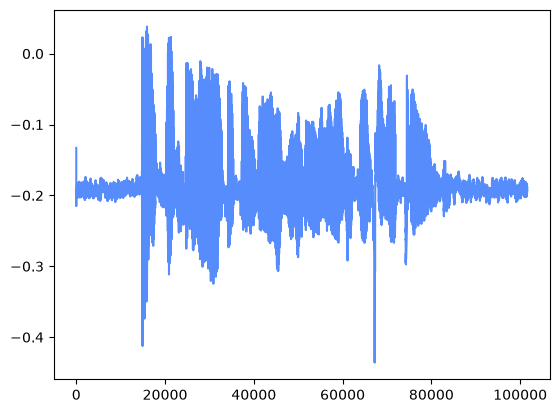

In [2]:
plt.plot(audio)
plt.show()

## Frequency Analysis

We can basically apply everything from the field of Signal Processing to speech! This means, the most important, is the Fourier Transform. If you don't know what the Fourier Transform is, watch this incredible video from [3Blue1Brown](https://youtu.be/spUNpyF58BY?feature=shared) that will visualize whats happening way better than I could ever write!

But lets do a quick primer just to get familiar with it, and how we can perform the Fourier Transform in PyTorch!

### Fourier Transform

$$X(k) = \sum_{n=0}^{N-1} x(n) \cdot e^{-i \frac{2\pi}{N} k n}$$


where:
- X(k) is the DFT of the signal,
- x(n) is the input signal,
- N is the number of samples,
- k is the frequency index,
- $e^{-i \frac{2\pi}{N} k n}$ is the complex exponential term.


We will be specifically working with the Discrete Fourier Transform (as our digital signals are sampled discretely), but they also have continuous ones that can be used for analog signals or anything else!

A Fourier Transform converts something from the Time (or Space) domain to the Frequency Domain. But what is frequency? Frequency is the number of cycles of a sinusoid that happens in a single second. Lets see what these sinusoids can look like!

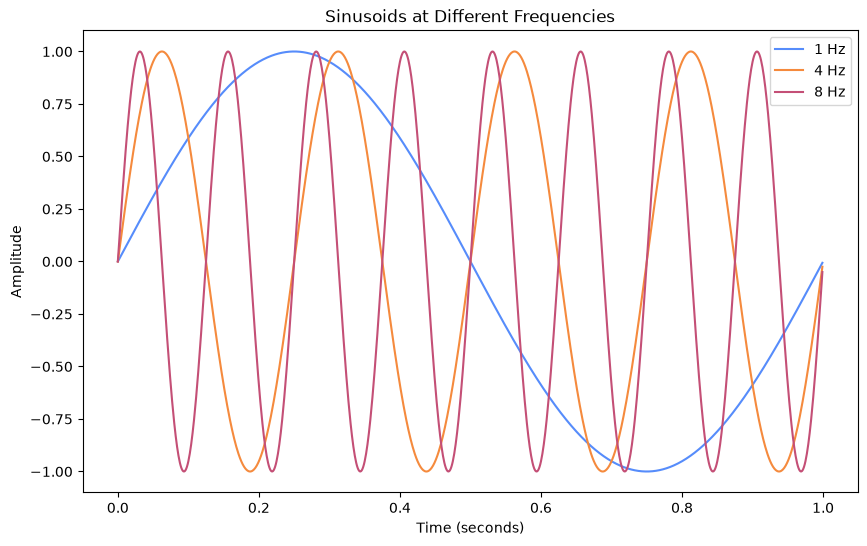

In [3]:
# Define parameters
t = np.linspace(0, 1, 1000, endpoint=False)  # Time vector (1 second, 1000 samples)
frequencies = [1, 4, 8]  # Different frequencies in Hz

# Plot sinusoids
plt.figure(figsize=(10, 6))
for f in frequencies:
    y = np.sin(2 * np.pi * f * t)
    plt.plot(t, y, label=f'{f} Hz')

plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Sinusoids at Different Frequencies')
plt.legend()
plt.show()

Lets take a look at the Fourier Transform! If we take a signal that we know has a frequency of 20, and apply a fourier transform to it, we should see a spike at 20Hz in the frequency domain and 0 elsewhere. 

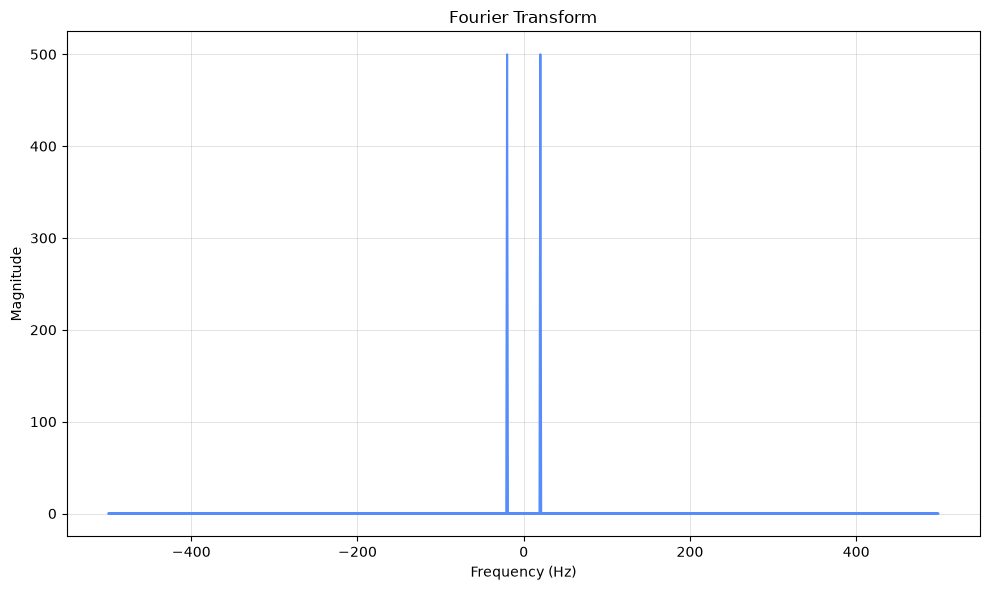

In [4]:
# Define parameters
t = np.linspace(0, 1, 1000, endpoint=False)  # Time vector (1 second, 1000 samples)
f = 20  # Single frequency in Hz

# Generate sinusoid
y = np.sin(2 * np.pi * f * t)

# Compute Fourier Transform
y_fft = np.fft.fft(y)
freqs = np.fft.fftfreq(len(t), d=t[1] - t[0])


plt.figure(figsize=(10, 6))
plt.plot(freqs, np.abs(y_fft))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Fourier Transform')
plt.grid(True)

plt.tight_layout()


### What did it do?
The output of a fourier transform is always a complex number:

$$F(y) = A + jB$$

The $A$ is the real part representing the cosine component, and $B$ is the imaginary part, representing the sine component.

But really, we are just decomposing any signal into a sum of sinusoids (at different frequencies, magnitudes, and phase shifts). Its just dealing with sin and cosine is a pain (think back on all those trigonometry identies!). This is why we represent everything with Eulers Formula:

$$e^{i\theta} = \cos(\theta) + i\sin(\theta)$$

And this is where the complex number shows up!

We can extract two things from this: Magnitude of the different frequencies and the Phase that tells us the shift of the frequency component

$$Magnitude = |F(y)| = \sqrt{A^2 + B^2}$$
$$Phase = \theta = \tan^{-1}(\frac{B}{A})$$

### Negative Frequencies?

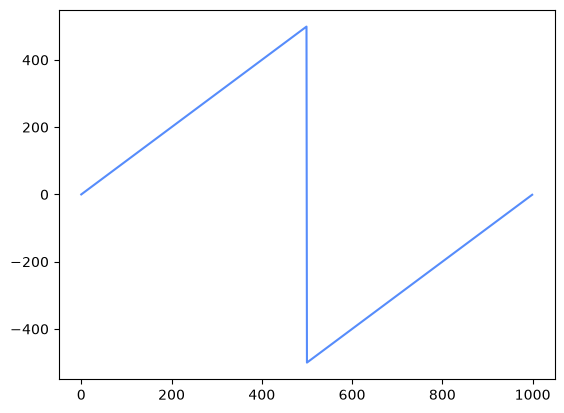

In [5]:
plt.plot(freqs)
plt.show()

Frequencies come in conjugate pairs, this means every frequency is paired with an identical negative frequency. We dont really care about them, so we typically only plot the positive frequencies

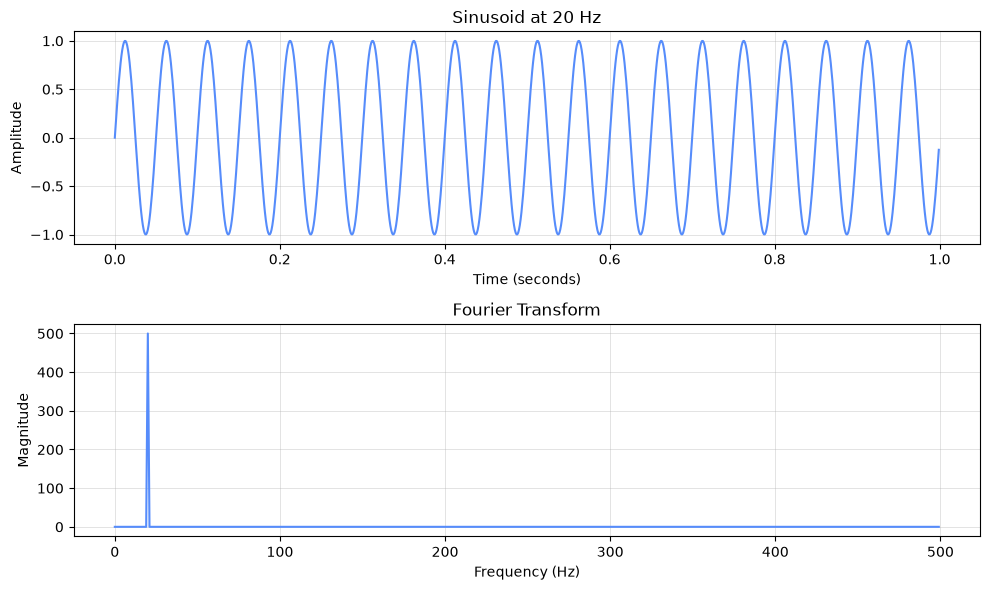

In [6]:
# Plot sinusoid
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(t, y)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title(f'Sinusoid at {f} Hz')
plt.grid(True)

# Plot Fourier Transform
plt.subplot(2, 1, 2)
plt.plot(freqs[:len(freqs)//2], np.abs(y_fft[:len(freqs)//2]))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Fourier Transform')
plt.grid(True)

plt.tight_layout()
plt.show()

### Nyquist-Shannon Sampling Theorem

A key part of signal processing is knowing what the maximum frequency a signal can represent. The theorem states that:

$$f_s > 2f_{max}$$

or the highest frequency a signal can represent is half the sampling rate. The signal we generated about had 1000 samples in 1 second, so the max frequency we can represent is 500! Can we see that in our data?

In [7]:
print("Max Frequency:", max(freqs))

Max Frequency: 499.0


This is especially important because, lets say you are recording audio for a song. The human hearing range typically goes to a frequency of about 20,000 , so we would need audio that is atleast 40,000 samples/second so we can contain all that information in nyquist. Typically we give ourselves a little buffer, and music will be recorded at about 44,100 samples/second.

When recording human speaking, the human voice has a much lower range, so we can use lower sampling rates like 16,000 samples/second

### Aliasing 

Unfortunately, this leads to a new issue: Aliasing. Lets say your audio is at 16,000 samples / second, and you have frequencies in it ranging all the way upto 5000. This means we can downsample our audio safely to 10,000 samples/second and maintain nyquist. But if we continue to downsample past that, then we start to lose frequeny information and Alias high frequencies to a different one. 

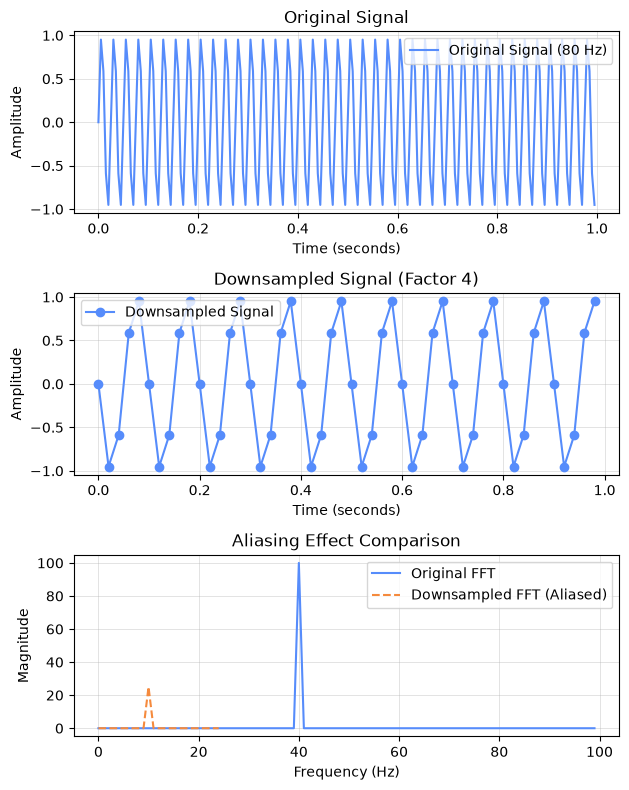

In [8]:
# Define parameters
t_high = np.linspace(0, 1, 200, endpoint=False)  # High-resolution time (1 second, 1000 samples)
f_original = 40  # Hz (Original frequency)

# Generate original sinusoid
y_high = np.sin(2 * np.pi * f_original * t_high)

# Compute Fourier Transform at high resolution
y_fft_high = np.fft.fft(y_high)
freqs_high = np.fft.fftfreq(len(t_high), d=t_high[1] - t_high[0])

# Downsampled version
downsample_factor = 4  # Reduce sampling rate by a factor of 4
t_low = t_high[::downsample_factor]
y_low = y_high[::downsample_factor]

# Compute Fourier Transform at lower sampling rate
y_fft_low = np.fft.fft(y_low)
freqs_low = np.fft.fftfreq(len(t_low), d=t_low[1] - t_low[0])

# Plot results
plt.figure(figsize=(12, 8))

# Original signal
plt.subplot(3, 2, 1)
plt.plot(t_high, y_high, label='Original Signal (80 Hz)')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Original Signal')
plt.legend()
plt.grid(True)

# Downsampled signal
plt.subplot(3, 2, 3)
plt.plot(t_low, y_low, 'o-', label='Downsampled Signal')
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title(f'Downsampled Signal (Factor {downsample_factor})')
plt.legend()
plt.grid(True)


# Highlight aliasing effect
plt.subplot(3, 2, 5)
plt.plot(freqs_high[:len(freqs_high)//2], np.abs(y_fft_high[:len(freqs_high)//2]), label='Original FFT')
plt.plot(freqs_low[:len(freqs_low)//2], np.abs(y_fft_low[:len(freqs_low)//2]), '--', label='Downsampled FFT (Aliased)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Aliasing Effect Comparison')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### Experiment: Hearing Aliasing

The 40 Hz example shows aliasing in a plot, but it's much more striking when you can **hear** it. Let's build a *chirp*: a sinusoid whose frequency sweeps linearly from 100 Hz to 7,900 Hz over 3 seconds, sampled at 16 kHz. Then we downsample it by 4 (to 4 kHz, so the new Nyquist limit is 2 kHz) in two ways:

1. **Naive:** just keep every 4th sample (`x[::4]`), exactly like we did above.
2. **Anti-aliased:** low-pass filter below the new Nyquist first, then drop samples. `scipy.signal.resample_poly` does this for us (and so does `torchaudio.functional.resample`).

Every frequency above 2 kHz has to go *somewhere* in the naive version. Watch (and listen) where it goes!

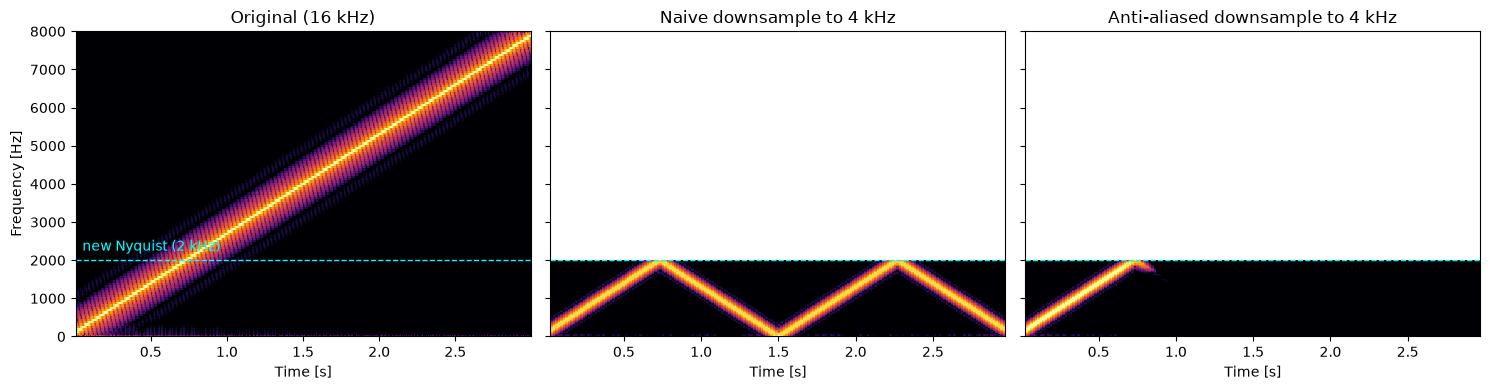

Original (16 kHz)


Naive downsample to 4 kHz


Anti-aliased downsample to 4 kHz


In [9]:
from scipy.signal import chirp, resample_poly
from scipy.signal import spectrogram as scipy_spectrogram

fs_chirp = 16000
t_chirp = np.arange(0, 3, 1 / fs_chirp)
sweep = 0.5 * chirp(t_chirp, f0=100, f1=7900, t1=3, method="linear")

factor = 4                                   # 16 kHz -> 4 kHz (new Nyquist = 2 kHz)
new_nyquist = fs_chirp / factor / 2

naive = sweep[::factor]                      # drop samples, no filtering
filtered = resample_poly(sweep, up=1, down=factor)  # low-pass filter, then drop samples

versions = [
    (sweep, fs_chirp, "Original (16 kHz)"),
    (naive, fs_chirp // factor, "Naive downsample to 4 kHz"),
    (filtered, fs_chirp // factor, "Anti-aliased downsample to 4 kHz"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (sig, rate, title) in zip(axes, versions):
    f_s, t_s, S = scipy_spectrogram(sig, fs=rate, nperseg=256, noverlap=192)
    ax.pcolormesh(t_s, f_s, 10 * np.log10(S + 1e-12), shading="auto", cmap="inferno", vmin=-90)
    ax.axhline(new_nyquist, color="cyan", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("Time [s]")
axes[0].set_ylabel("Frequency [Hz]")
axes[0].text(0.05, new_nyquist + 250, "new Nyquist (2 kHz)", color="cyan")
plt.ylim(0, fs_chirp / 2)
plt.tight_layout()
plt.show()

for sig, rate, title in versions:
    print(title)
    IPython.display.display(IPython.display.Audio(sig, rate=rate))

In the naive version the sweep hits 2 kHz and then **bounces back down**, then up again, in a zig-zag: frequencies above Nyquist get "folded" back into the valid range ($f_{alias} = |f - k \cdot f_s|$). You can hear it go up and down, even though the real signal only ever goes up! The anti-aliased version just goes quiet once the sweep passes 2 kHz. That's the correct behavior, since that information can't exist at a 4 kHz sampling rate.

**Takeaway:** when you resample audio for a model (e.g. 44.1 kHz music down to 16 kHz), always use a proper resampler like `torchaudio.functional.resample`, never plain slicing.

### Sum of Sinusoids

The coolest part about fourier transforms though is that, if we have a single, that is a mixture of multiple sinusoids, then the fourier transform can identify the frequency of all the the individual sinusoids that make it! For example:


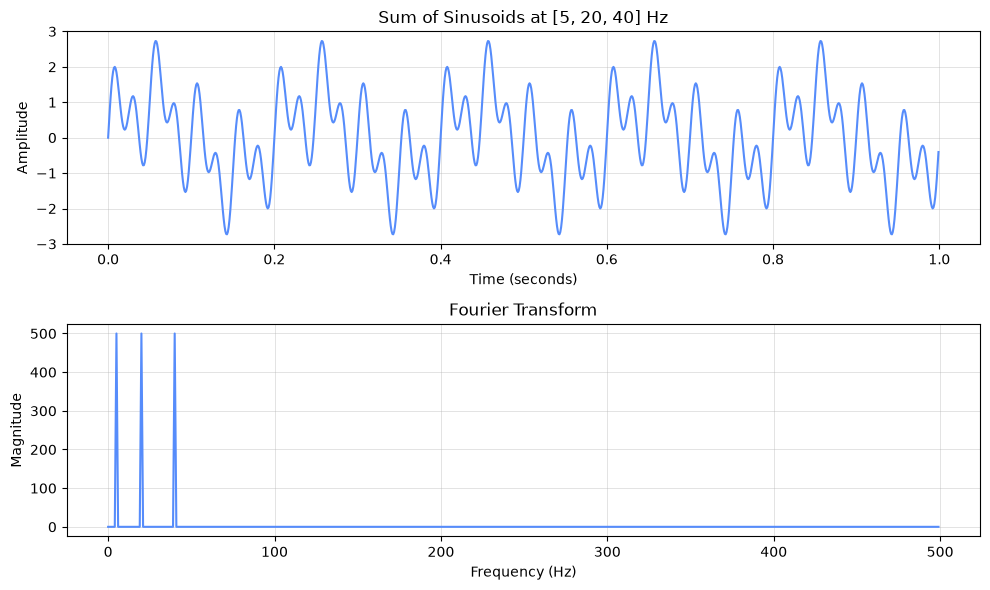

In [10]:
# Define parameters
t = np.linspace(0, 1, 1000, endpoint=False)  # Time vector (1 second, 1000 samples)
frequencies = [5, 20, 40]  # Multiple frequencies in Hz

# Generate sum of sinusoids
y = np.sum([np.sin(2 * np.pi * f * t) for f in frequencies], axis=0)

# Compute Fourier Transform
y_fft = np.fft.fft(y)
freqs = np.fft.fftfreq(len(t), d=t[1] - t[0])

# Plot summed sinusoids
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(t, y)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title(f'Sum of Sinusoids at {frequencies} Hz')
plt.grid(True)

# Plot Fourier Transform
plt.subplot(2, 1, 2)
plt.plot(freqs[:len(freqs)//2], np.abs(y_fft[:len(freqs)//2]))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Fourier Transform')
plt.grid(True)

plt.tight_layout()
plt.show()


### Inverse Transform

Can we go from frequency back to to the time domain? Of course! We can use the Inverse Fourier transform. We can pass in our complex values from the fourier transform to our inverse transform and get back the original signal! 

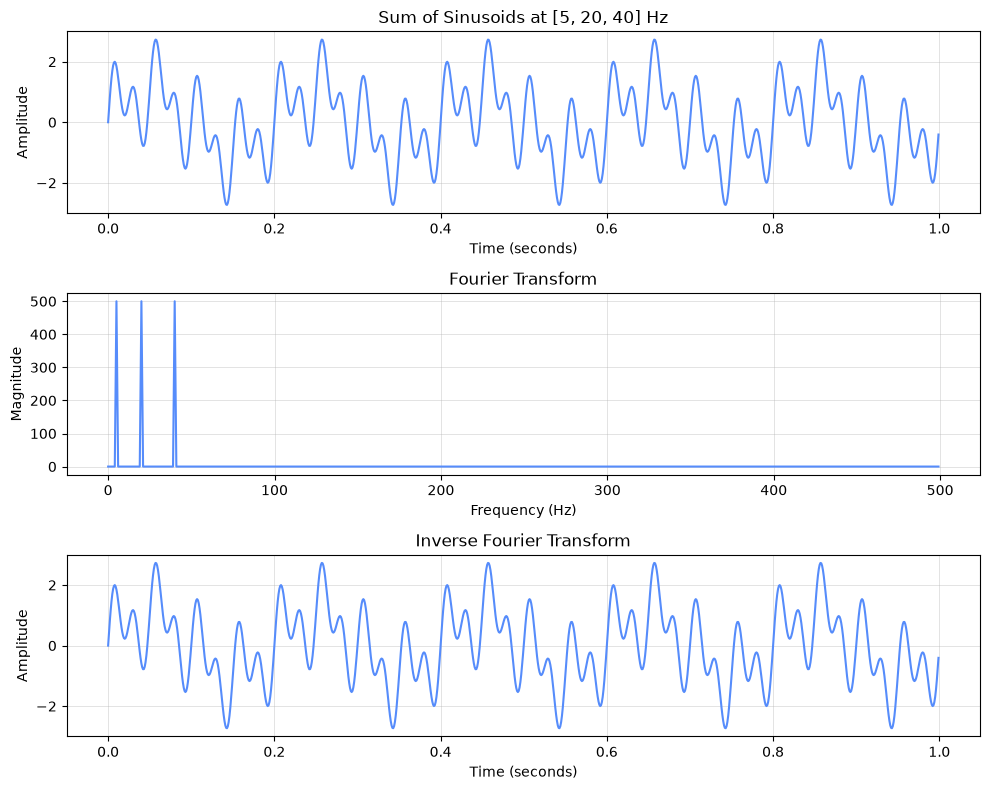

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Define parameters
t = np.linspace(0, 1, 1000, endpoint=False)  # Time vector (1 second, 1000 samples)
frequencies = [5, 20, 40]  # Multiple frequencies in Hz

# Generate sum of sinusoids
y = np.sum([np.sin(2 * np.pi * f * t) for f in frequencies], axis=0)

# Compute Fourier Transform
y_fft = np.fft.fft(y)
freqs = np.fft.fftfreq(len(t), d=t[1] - t[0])

# Compute Inverse Fourier Transform
y_ifft = np.fft.ifft(y_fft).real

# Plot summed sinusoids
plt.figure(figsize=(10, 8))

plt.subplot(3, 1, 1)
plt.plot(t, y)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title(f'Sum of Sinusoids at {frequencies} Hz')
plt.grid(True)

# Plot Fourier Transform
plt.subplot(3, 1, 2)
plt.plot(freqs[:len(freqs)//2], np.abs(y_fft[:len(freqs)//2]))
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Fourier Transform')
plt.grid(True)

# Plot Inverse Fourier Transform
plt.subplot(3, 1, 3)
plt.plot(t, y_ifft)
plt.xlabel('Time (seconds)')
plt.ylabel('Amplitude')
plt.title('Inverse Fourier Transform')
plt.grid(True)

plt.tight_layout()
plt.show()

### Spectrograms: Frequency vs Time

It seems like we are doing a full conversion here. We are either completely in the time domain or converting to the frequency domain. This is probably less useful to use though. In human speaking, what we are curious about is the frequency at different times of the audio! This is also known as a ```Short Time Fourier Transform``` (STFT). This is because we can learn that different combinations of frequencies typically make different sounds, which a Neural Network can pick up on to do things like Voice to Text.

A spectrogram is like a picture of the audio and the idea is very simple. Take an audio that has maybe 160000 samples at 16000 samples/second (10 seconds of audio) and compute the Fourier Transform that we saw above on small consecutive chunks of it. Then just put it all together into a plot!

Therefore, there a few things you have to decide:
- n_fft: How many samples do you want in every chunk?
- hop_length: How many samples do you want to move over every time?

Its pretty typically to have a 50% overlap, so the hop length is half the n_fft. 


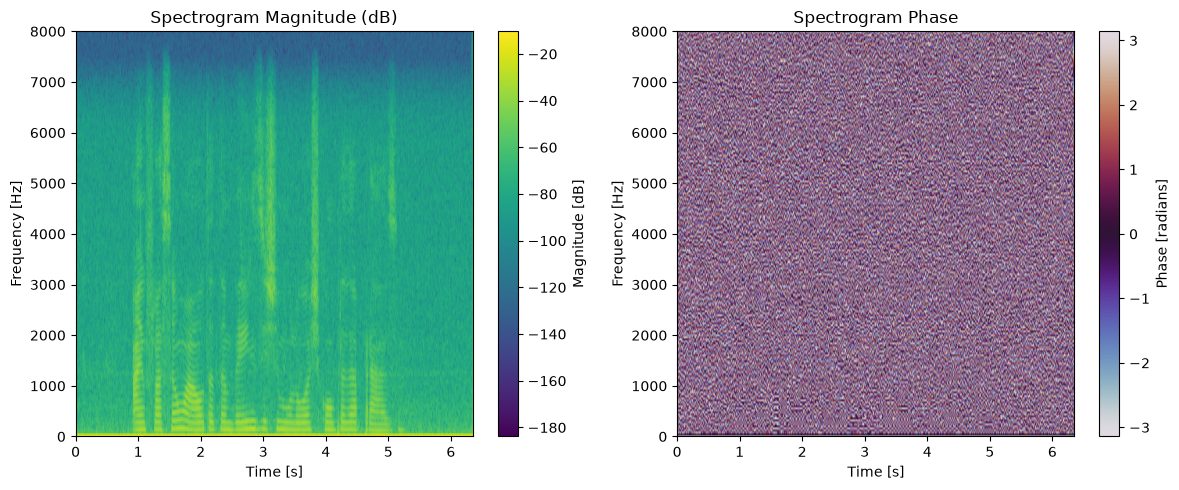

In [12]:
from scipy.signal import stft

# Compute complex spectrogram using STFT
f, t_spec, Zxx = stft(audio, fs=16000, nperseg=400, noverlap=200)

# Magnitude and Phase
magnitude = np.abs(Zxx)
phase = np.angle(Zxx)

# Plot magnitude
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.pcolormesh(t_spec, f, 20 * np.log10(magnitude + 1e-10), shading='gouraud')
plt.title('Spectrogram Magnitude (dB)')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(label='Magnitude [dB]')

# Plot phase
plt.subplot(1, 2, 2)
plt.pcolormesh(t_spec, f, phase, shading='gouraud', cmap='twilight')
plt.title('Spectrogram Phase')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar(label='Phase [radians]')

plt.tight_layout()
plt.show()

#### Magnitude Only

Although the phase information is important, it doesnt seem to have any clear information in it! So instead we simply use the magnitude of the frequencies. This will lead to a different problem later, but for now we can keep going!

Lets create a spectrogram on our audio from before using Torch:

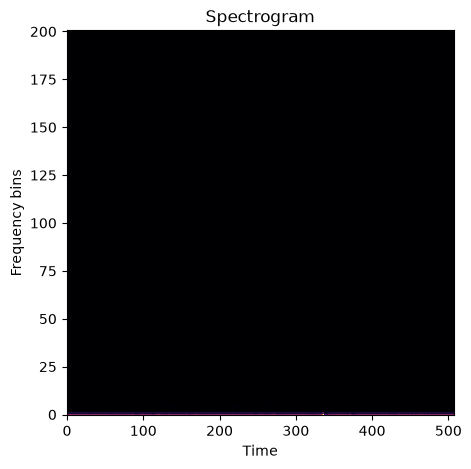

In [13]:
# Apply a regular Spectrogram transformation (not MelSpectrogram)
transform = T.Spectrogram(n_fft=400, hop_length=200)
spec = transform(audio)

# Plot the spectrogram
plt.figure(figsize=(5, 5))
plt.imshow(spec, cmap='inferno', origin='lower', aspect='auto', interpolation='none')
plt.title("Spectrogram")
plt.ylabel("Frequency bins")
plt.xlabel("Time")
plt.show()

That doesn't look like much... This is beacause instead of looking at raw amplitudes, we typically convert our spectrogram to decibels! This is basically a log scaling of our spectrogram (which is amplitude of the different frequencies) like the following

$$dB = 20 * \log_{10}(P)$$

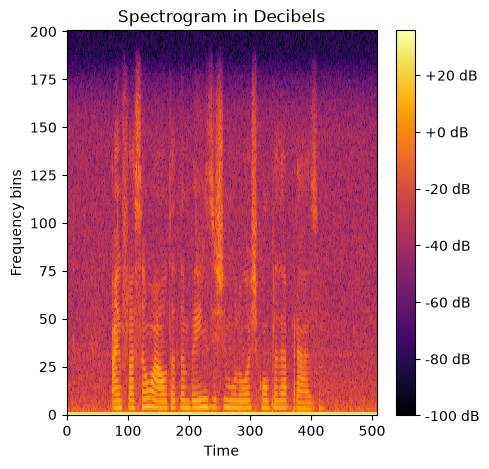

In [14]:
db_transform = T.AmplitudeToDB()
db_spec = db_transform(spec)

# Plot the decibel spectrogram
plt.figure(figsize=(5, 5))
plt.imshow(db_spec.numpy(), cmap='inferno', origin='lower', aspect='auto', interpolation='none')
plt.colorbar(format="%+2.0f dB")
plt.title("Spectrogram in Decibels")
plt.ylabel("Frequency bins")
plt.xlabel("Time")
plt.show()

### Experiment: The Time-Frequency Trade-off

`n_fft` isn't just a hyperparameter you set and forget. It controls a fundamental trade-off (a version of the **uncertainty principle**):

- **Frequency resolution** is $\Delta f = \frac{f_s}{n\_fft}$ Hz per bin. Bigger windows mean finer frequency detail.
- **Time resolution** is roughly the window length $\frac{n\_fft}{f_s}$ seconds. Bigger windows smear events across time.

You can't have both. Let's look at the same audio with three window sizes:

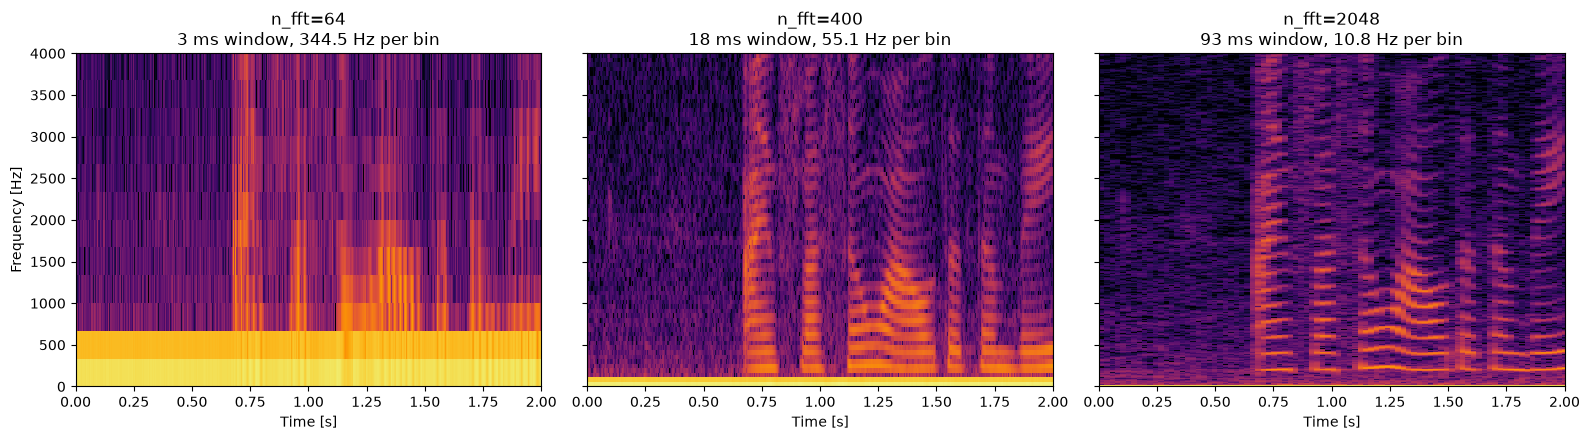

In [15]:
n_ffts = [64, 400, 2048]
duration = len(audio) / sampling_rate

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, n_fft in zip(axes, n_ffts):
    spec_k = T.Spectrogram(n_fft=n_fft, hop_length=n_fft // 4)(audio)
    spec_k_db = T.AmplitudeToDB(top_db=80)(spec_k)
    ax.imshow(spec_k_db.numpy(), origin="lower", aspect="auto", cmap="inferno",
              interpolation="none", extent=[0, duration, 0, sampling_rate / 2])
    ax.set_title(f"n_fft={n_fft}\n{1000 * n_fft / sampling_rate:.0f} ms window, "
                 f"{sampling_rate / n_fft:.1f} Hz per bin")
    ax.set_xlabel("Time [s]")
    ax.set_xlim(0, min(duration, 2.0))     # zoom into the first 2 seconds
    ax.set_ylim(0, 4000)                   # most speech energy lives here
axes[0].set_ylabel("Frequency [Hz]")
plt.tight_layout()
plt.show()

### Mel Spectrogram

The Mel Spectrogram is very close to what we have done so far, but is a special type of spectrogram that uses a MEL Scale. This is a perceptual scale that spaces frequencies more widely at higher frequencies and more closer together at lower frequencies (therefore a non-linear frequency scale). The Mel Spectrogram is closer to the what the human ear percieves sound and is an approximation of our auditory perception. 

$$Mel(f) = 1127\ln(\frac{f}{700} + 1)$$

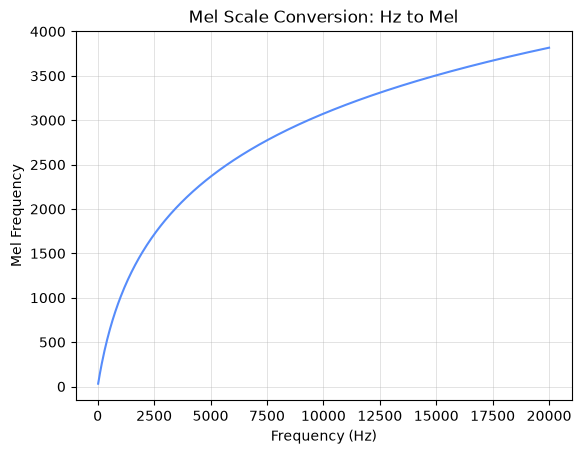

In [16]:
def hz_to_mel(f):
    return 1127 * np.log(1 + f / 700)

frequencies = np.linspace(20, 20000, 500)
mel_frequencies = hz_to_mel(frequencies)

plt.plot(frequencies, mel_frequencies)
plt.title('Mel Scale Conversion: Hz to Mel')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mel Frequency')
plt.grid(True)

### Create a Mel Spectrogram

There are some key arguments you need to set again:
- sample_rate: what is the sampling rate of the audio?
- n_fft: window size for the transform
- hop_length: how much to move every step?
- n_mels: larger n_mels gives higher frequency resolution and more detail, whereas fewer gives less detail. You can only generative n_mels upto the number of frequency bins from the FFT.
- mel_scale: There are slight differences in definitions for scaling for mel frequencies (slaney vs htk)

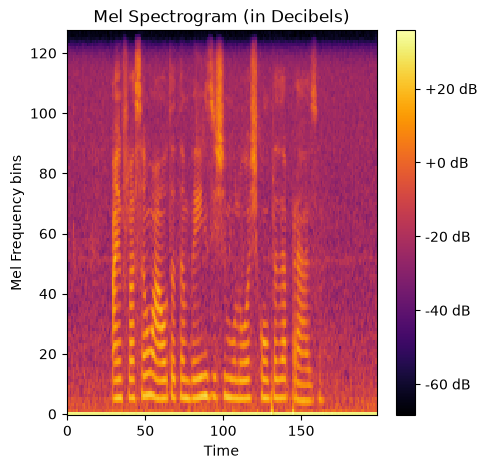

In [17]:
# Define MelSpectrogram transformation
transform = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,             # FFT window size
    hop_length=512,        # Hop length (stride)
    n_mels=128,             # Number of Mel bins
    mel_scale="slaney"        # Mel scale (HTK or Slaney)
)

# Apply the MelSpectrogram transform to the waveform
mel_spec = transform(audio)

# Convert the Mel spectrogram to decibels (dB)
db_transform = T.AmplitudeToDB()
mel_spec_db = db_transform(mel_spec)

# Plot the Mel spectrogram
plt.figure(figsize=(5, 5))
plt.imshow(mel_spec_db.numpy(), cmap='inferno', origin='lower', aspect='auto', interpolation='none')
plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram (in Decibels)")
plt.ylabel("Mel Frequency bins")
plt.xlabel("Time")
plt.show()

### MFCCs (Mel-Frequency Cepstral Coefficients)

Before deep learning took over, MFCCs were *the* feature for speech recognition (and they're still common in small models, speaker ID and classic ML pipelines). They take just one more step on top of the log-Mel spectrogram:

$$MFCC = DCT\big(\log(\text{Mel Spectrogram})\big)$$

For every time frame, we apply a **Discrete Cosine Transform** across the mel bins and keep only the first ~13 coefficients. Why?

- **Source-filter model:** speech is a *source* (the vocal folds vibrating at some pitch, which creates fine, fast-wiggling harmonics across frequency) shaped by a *filter* (your throat, tongue and lips, which create a smooth envelope with peaks called *formants*). The filter is what tells you *which sound* is being said.
- In the log domain these two get **added** together. The DCT is like a Fourier transform of the spectrum itself: the smooth envelope lands in the **low** coefficients and the fast harmonic wiggles land in the **high** ones.
- Keeping only the first 13 coefficients throws away the pitch and keeps the "what was said" part. It's also a compact, mostly decorrelated feature (13 numbers per frame instead of 128).

### Experiment: What Do 13 Coefficients Keep?

Let's take our log-Mel spectrogram, compute the DCT, keep only the first `k` coefficients, and invert it back. This shows exactly what information MFCCs keep:

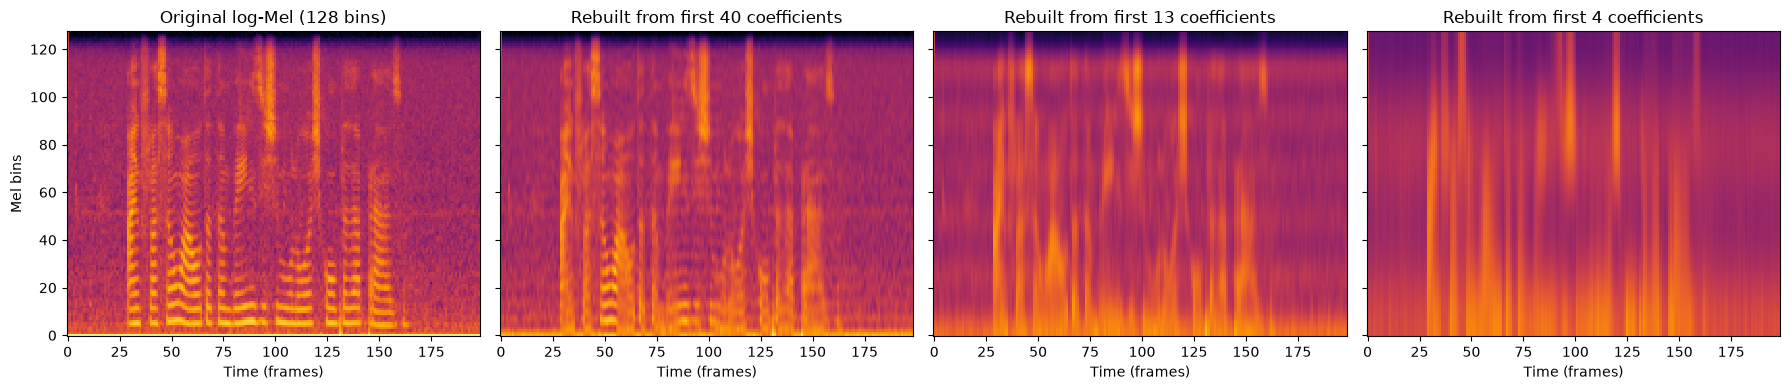

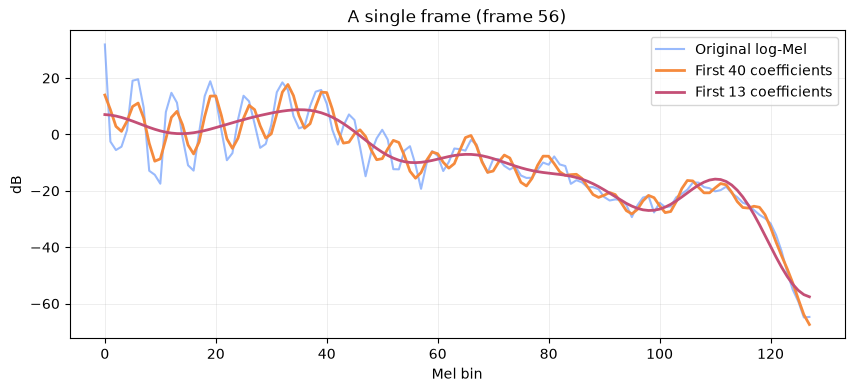

In [18]:
from scipy.fft import dct, idct

log_mel = mel_spec_db.numpy()                       # (n_mels, time), from the cell above
cepstrum = dct(log_mel, type=2, norm="ortho", axis=0)   # DCT across the mel axis

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
axes[0].imshow(log_mel, origin="lower", aspect="auto", cmap="inferno", interpolation="none")
axes[0].set_title("Original log-Mel (128 bins)")
for ax, k in zip(axes[1:], [40, 13, 4]):
    truncated = np.zeros_like(cepstrum)
    truncated[:k] = cepstrum[:k]                    # keep only the first k coefficients
    recon = idct(truncated, type=2, norm="ortho", axis=0)
    ax.imshow(recon, origin="lower", aspect="auto", cmap="inferno", interpolation="none",
              vmin=log_mel.min(), vmax=log_mel.max())
    ax.set_title(f"Rebuilt from first {k} coefficients")
for ax in axes:
    ax.set_xlabel("Time (frames)")
axes[0].set_ylabel("Mel bins")
plt.tight_layout()
plt.show()

# Zoom into a single frame to compare the envelopes
frame = log_mel.var(axis=0).argmax()   # pick a frame with lots of detail
plt.figure(figsize=(10, 4))
plt.plot(log_mel[:, frame], label="Original log-Mel", alpha=0.6)
for k in [40, 13]:
    truncated = np.zeros_like(cepstrum[:, frame])
    truncated[:k] = cepstrum[:k, frame]
    plt.plot(idct(truncated, type=2, norm="ortho"), label=f"First {k} coefficients", lw=2)
plt.xlabel("Mel bin")
plt.ylabel("dB")
plt.title(f"A single frame (frame {frame})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

With 13 coefficients the fine detail disappears, but the **broad shape** of the spectrum (where the energy peaks are, which is what distinguishes an "ah" from an "ee") survives. With only 4, even that starts to go. That's why 13 is the classic choice: it keeps enough to recognize phonemes while dropping speaker-specific detail like pitch.

### MFCCs in torchaudio

In practice you don't do this by hand. `T.MFCC` does mel spectrogram DCT in one go. A typical speech setup uses 25 ms windows, a 10 ms hop and 40 mel bins. It's also very common to stack the **deltas** (how each coefficient changes over time, like a velocity) and **delta-deltas** (acceleration), giving 39 features per frame:

MFCC shape: (13, 635) | with deltas: (39, 635)


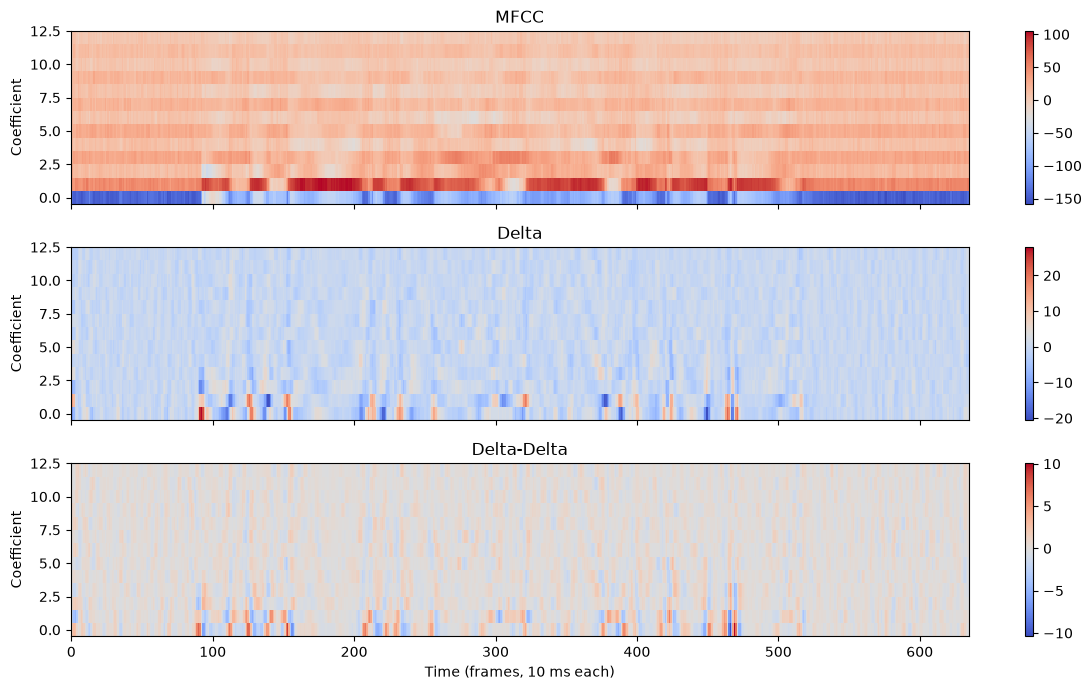

In [19]:
mfcc_transform = T.MFCC(
    sample_rate=sampling_rate,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 40, "mel_scale": "htk"},
)
mfcc = mfcc_transform(audio)                  # (13, time)
deltas = T.ComputeDeltas()(mfcc)              # velocity
delta_deltas = T.ComputeDeltas()(deltas)      # acceleration
features = torch.cat([mfcc, deltas, delta_deltas], dim=0)
print("MFCC shape:", tuple(mfcc.shape), "| with deltas:", tuple(features.shape))

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, (data, title) in zip(axes, [(mfcc, "MFCC"), (deltas, "Delta"), (delta_deltas, "Delta-Delta")]):
    im = ax.imshow(data.numpy(), origin="lower", aspect="auto", cmap="coolwarm", interpolation="none")
    ax.set_title(title)
    ax.set_ylabel("Coefficient")
    fig.colorbar(im, ax=ax)
axes[-1].set_xlabel("Time (frames, 10 ms each)")
plt.tight_layout()
plt.show()

Notice that coefficient 0 (the bottom row) looks very different from the rest. It's basically the **overall loudness** of the frame, which is why some pipelines drop it or replace it with a separate energy feature. Also, MFCCs are usually **normalized per coefficient** (subtract the mean, divide by the std over the utterance, a.k.a. CMVN) before going into a model, since their scales vary wildly.

**MFCC vs Mel Spectrogram today:** the DCT was useful for older models (like Gaussian Mixture Models) that liked decorrelated features. Neural networks, especially CNNs, are happy to learn from the full log-Mel spectrogram directly, so most modern models (Whisper, for example) use log-Mel and skip the DCT.

### The Problem of No Phase

In TTS systems (Text to Speech) a typical strategy is to use a Neural Network to predict this spectrogram! But this spectrogram is only the magnitude information of the original audio and not the phase. This prohibits us from directly doing an inverse short time fourier transform as we saw earlier, when we did the inverse of the fourier transform, we passed in the complex values as it contains both magnitude and phase information.

Therefore how do we inverse? The Griffin Lim Algorithm!

### Griffin-Lim Algorithm

The Griffin-Lim algorithm is an iterative method used for phase retrieval in the context of inverse spectrogram reconstruction. It is typically used to reconstruct a time-domain signal from a magnitude spectrogram when the phase information is missing.

Steps:

1) Start with an initial guess for the phase
2) Inverse STFT back to the waveform with the current phase guess
3) Take the STFT again back to the spectrogram
4) Rescale so the magnitude of our new spectrogram is the same as the original spectrogram.
5) Repeat when converged!

There are a lot of cool reasons this works, and you can explore this at my [professors slides!](https://courses.grainger.illinois.edu/ece417/fa2023/slides/lec06.pdf)

The main reason though is we are trying to solve a constrained optimization, and the way that STFT and Inverse STFT works, you are effectively doing projections between your constraints until you have solved the system. 

Maybe in the future I can do a simple implementation of this, but for now lets just use ```torchaudio```

### InverseMelScale

Griffin Lim only works on the linear scale spectrogram, not the Mel Scale, so we have to convert our Mel Spectrogram back to the linear scale, and then we can do griffin lim!

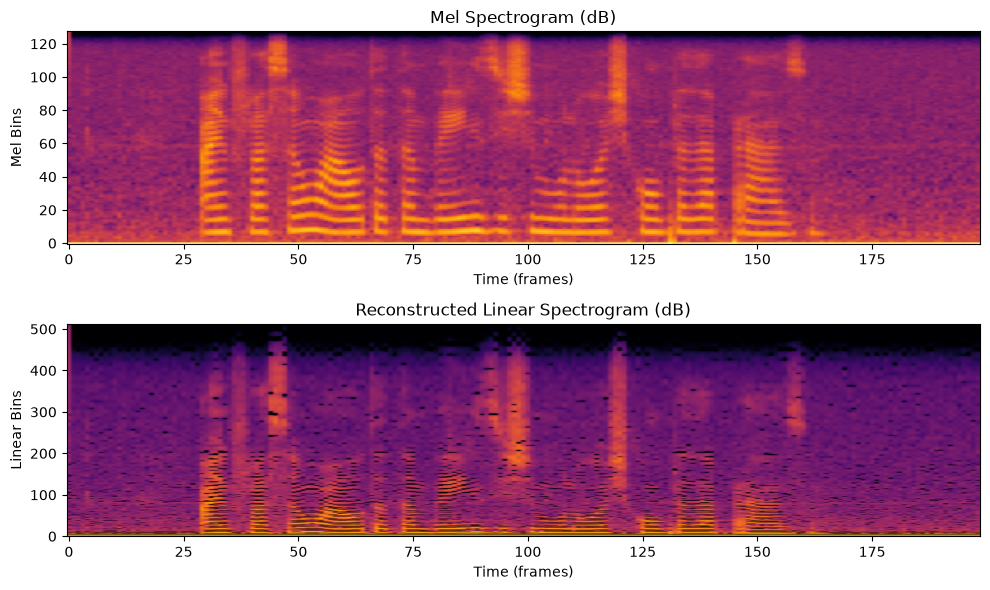

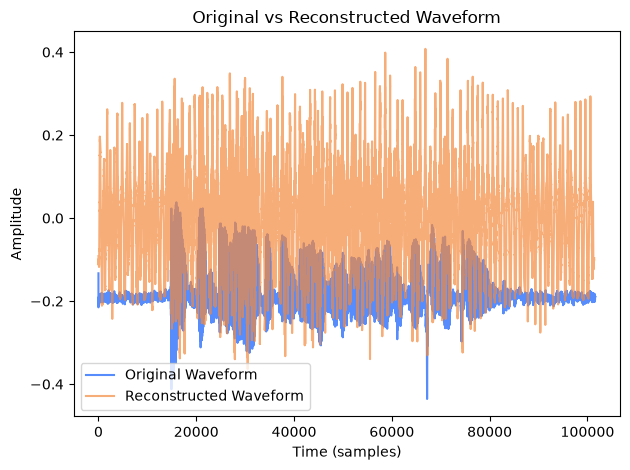

In [20]:
waveform, sample_rate = torchaudio.load("audio.wav")

transform = T.MelSpectrogram(
    sample_rate=sample_rate,
    n_fft=1024,             # FFT window size
    hop_length=512,        # Hop length (stride)
    n_mels=128,             # Number of Mel bins
    mel_scale="slaney"        # Mel scale (HTK or Slaney)
)

mel_spectrogram = transform(waveform)

### Convert Mel to Linear ###
inverse_melscale_transform = T.InverseMelScale(n_stft=1024//2+1, 
                                               n_mels=128, 
                                               sample_rate=sample_rate,
                                               mel_scale="slaney")
spectrogram = inverse_melscale_transform(mel_spectrogram)

# Apply Griffin-Lim algorithm to reconstruct the waveform from the magnitude spectrogram
griffin_lim_transform = T.GriffinLim(n_fft=1024, hop_length=512, n_iter=100)
reconstructed_waveform = griffin_lim_transform(spectrogram)

# Plot the Mel spectrogram and the reconstructed regular spectrogram
plt.figure(figsize=(10, 6))

# Plot Mel Spectrogram (in dB)
plt.subplot(2, 1, 1)
plt.imshow(torch.log(mel_spectrogram[0] + 1e-6).numpy(), aspect='auto', origin='lower', cmap='inferno')
plt.title('Mel Spectrogram (dB)')
plt.xlabel('Time (frames)')
plt.ylabel('Mel Bins')

# Plot the reconstructed Linear Spectrogram (in dB)
plt.subplot(2, 1, 2)
plt.imshow(torch.log(spectrogram[0] + 1e-6).numpy(), aspect='auto', origin='lower', cmap='inferno')
plt.title('Reconstructed Linear Spectrogram (dB)')
plt.xlabel('Time (frames)')
plt.ylabel('Linear Bins')

plt.tight_layout()
plt.show()

# Plot the Original and Reconstructed Waveforms
plt.plot(waveform.t().numpy(), label='Original Waveform')
plt.plot(reconstructed_waveform.t().numpy(), label='Reconstructed Waveform', alpha=0.7)
plt.title('Original vs Reconstructed Waveform')
plt.xlabel('Time (samples)')
plt.ylabel('Amplitude')
plt.legend()

plt.tight_layout()
plt.show()

IPython.display.Audio(reconstructed_waveform, rate=sample_rate)


### Experiment: Griffin-Lim From Scratch (and Why Phase Matters)

Let's implement the 5 steps above ourselves. It's only a few lines with `torch.stft` / `torch.istft`. We'll skip the mel step and start from the *true* linear magnitude, so the only thing missing is the phase. Two questions:

1. How bad is it to just use the correct magnitude with a **random phase**? (That's iteration 0 of Griffin-Lim.)
2. How quickly does Griffin-Lim recover? We'll track the **spectral convergence**, which measures how far the magnitude of our current waveform is from the target:

$$SC = \frac{\| \, |STFT(\hat{x})| - |X| \, \|_F}{\| \, |X| \, \|_F}$$

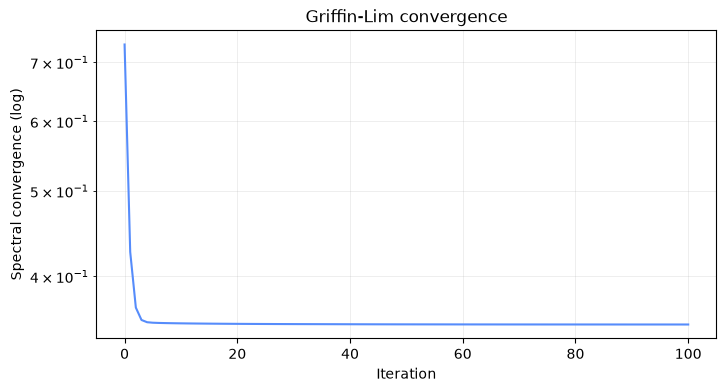

Original


Correct magnitude + random phase (no Griffin-Lim)  |  SC = 0.733


Correct magnitude + after 5 iterations  |  SC = 0.354


Correct magnitude + after 100 iterations  |  SC = 0.353


In [21]:
n_fft_gl, hop_gl = 1024, 256
window_gl = torch.hann_window(n_fft_gl)

def stft(x):
    return torch.stft(x, n_fft_gl, hop_length=hop_gl, window=window_gl, return_complex=True)

def istft(X):
    return torch.istft(X, n_fft_gl, hop_length=hop_gl, window=window_gl, length=len(audio))

target_mag = stft(audio).abs()   # we keep the magnitude and throw the phase away

def griffin_lim(mag, n_iter=100, snapshots=(0, 5, 100)):
    torch.manual_seed(0)
    X_est = torch.polar(mag, 2 * torch.pi * torch.rand_like(mag))  # 1) random initial phase
    errors, saved = [], {}
    for i in range(n_iter + 1):
        x = istft(X_est)                                          # 2) back to a waveform
        if i in snapshots:
            saved[i] = x
        X_new = stft(x)                                           # 3) back to a spectrogram
        errors.append((torch.linalg.norm(X_new.abs() - mag) / torch.linalg.norm(mag)).item())
        X_est = torch.polar(mag, X_new.angle())                   # 4) keep the phase, restore the magnitude
    return saved, errors

saved, errors = griffin_lim(target_mag)

plt.figure(figsize=(8, 4))
plt.plot(errors)
plt.yscale("log")
plt.xlabel("Iteration")
plt.ylabel("Spectral convergence (log)")
plt.title("Griffin-Lim convergence")
plt.grid(True, which="both", alpha=0.3)
plt.show()

print("Original")
IPython.display.display(IPython.display.Audio(audio, rate=sampling_rate))
for i, x in saved.items():
    label = "random phase (no Griffin-Lim)" if i == 0 else f"after {i} iterations"
    print(f"Correct magnitude + {label}  |  SC = {errors[i]:.3f}")
    IPython.display.display(IPython.display.Audio(x, rate=sampling_rate))

With random phase the magnitude is *exactly* right, yet the audio sounds rough and "whispery" and is barely intelligible. Phase carries a lot of the structure that lines up neighboring frames! Griffin-Lim fixes most of it in the first few iterations, then improves slowly. Even after 100 iterations it never reaches zero error and keeps a slightly metallic, "phasey" quality. That leftover artifact is exactly what neural vocoders like HiFi-GAN were built to remove.

**Try it yourself:** change `hop_gl` to `512` (50% overlap instead of 75%) and rerun. The spectral convergence may actually come out *lower*, because with fewer overlapping frames there are fewer constraints to satisfy. Now listen to both versions. Does a lower SC always mean better-sounding audio?

### Vocoders

Although Griffin Lim can create reasonable reconstructions from Magnitude Spectrograms to Audio, it isn't as good as Deep Learning based methods like HIFI-GAN. These are typically known as Vocoders (or speech synthesizers). We will be exploring how to build these in the future!


## Recap

You should have a good idea now about some of the techniques we use from Signal Processing to prep Audio data from training neural networks! There are still more stuff that we didn't discuss (VAD, Formant Analysis, Pitch Detection, Speaker Identification, etc...) but we will get into all of this in the future!